<a href="https://colab.research.google.com/github/shilnikovAD/workchat-agent/blob/main/hw3/homework03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
from pathlib import Path
if not any(Path(p, "fresh_2026.jsonl").exists() for p in ["data", "../hw1/data", "workchat-agent/hw3/data", "workchat-agent/hw1/data"]):
    !git clone -q https://github.com/shilnikovAD/workchat-agent
try:
    from google.colab import userdata
    os.environ.setdefault("OPENROUTER_API_KEY", userdata.get("OPENROUTER_API_KEY"))
except Exception:
    pass

In [2]:
%pip install -q httpx pydantic python-dotenv pandas matplotlib "langgraph>=1.0" "langchain>=1.0" "langchain-openai>=1.0"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\artsh\hw4env-win\Scripts\python.exe -m pip install --upgrade pip


In [3]:

import os, re, json, gzip, time, warnings, difflib
os.environ.setdefault("LANGCHAIN_OPENAI_TCP_KEEPALIVE", "0")
warnings.filterwarnings("ignore")
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from typing import TypedDict
import httpx
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from dotenv import load_dotenv
load_dotenv()

KEY = os.getenv("OPENROUTER_API_KEY")
assert KEY, "нет ключа OPENROUTER_API_KEY"

BASE_URL = "https://openrouter.ai/api/v1"
CHEAP, STRONG = os.getenv("CHEAP_MODEL", "openai/gpt-4o-mini"), os.getenv("STRONG_MODEL", "anthropic/claude-sonnet-4.6")
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = next((p for p in [Path("data"), Path("../hw1/data"), Path("workchat-agent/hw3/data"), Path("workchat-agent/hw1/data")] if (p / "fresh_2026.jsonl").exists()), Path("data"))
# выборка 40 вопросов: 20 из стартового набора (fresh-0 … fresh-19) и все 20 своих русских (fresh-125 … fresh-144)
SEMINAR_N, OWN_FROM = 20, 125
Path("results").mkdir(exist_ok=True)
Path("img").mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 200)

def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

def pmap(fn, items, workers=6):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(fn, items))

In [4]:
CALLS, FIRST, TAG = [], {}, {"now": "без метки"}

def on_response(response):
    response.read()
    if response.status_code != 200:
        return
    request = json.loads(response.request.content or b"{}")
    usage = response.json().get("usage") or {}
    FIRST.setdefault(TAG["now"], request)
    CALLS.append({
        "tag": TAG["now"],
        "model": request.get("model", "?").split("/")[-1],
        "messages": len(request.get("messages", [])),
        "tools": len(request.get("tools", [])),
        "bytes": len(response.request.content or b""),
        "prompt": usage.get("prompt_tokens", 0),
        "completion": usage.get("completion_tokens", 0),
        "cost": usage.get("cost") or 0,
    })

HTTP = httpx.Client(event_hooks={"response": [on_response]}, timeout=180)
HEADERS = {"Authorization": f"Bearer {KEY}", "X-Title": "agents-course-homework03"}

def chat(messages, model=CHEAP, tools=None, temperature=0.0):
    body = {"model": model, "messages": messages, "temperature": temperature, "max_tokens": 1024}
    if tools:
        body["tools"] = tools
    for attempt in range(5):
        r = HTTP.post(f"{BASE_URL}/chat/completions", json=body, headers=HEADERS)
        if r.status_code == 200 and "choices" in r.json():
            return r.json()["choices"][0]["message"]
        time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"HTTP {r.status_code}: {r.text[:200]}")

TAG["now"] = "проверка счётчика"
chat([{"role": "user", "content": "Say OK"}])
pd.DataFrame(CALLS)

,tag,model,messages,tools,bytes,prompt,completion,cost
0,проверка счётчика,gpt-4o-mini,1,0,114,9,2,0.000003


In [5]:
ALL = load_jsonl("fresh_2026.jsonl")
num = lambda t: int(t["id"].split("-")[1])
tasks = [t for t in ALL if num(t) < SEMINAR_N] + [t for t in ALL if num(t) >= OWN_FROM]
WIKI = "https://{lang}.wikipedia.org/w/api.php"
WIKI_HEADERS = {"User-Agent": "agents-course-seminar03/1.0 (https://t.me/artemovma)"}
SNAPSHOT = Path("results") / "wiki_snapshot.json.gz"   # кэш ответов Википедии: повторный прогон не упирается в лимиты
WIKI_ERRORS = []
WIKI_CACHE = json.loads(gzip.decompress(SNAPSHOT.read_bytes())) if SNAPSHOT.exists() else {}

def wiki(params, lang="en"):
    key = json.dumps({**params, "lang": lang} if lang != "en" else params, sort_keys=True)
    for attempt in range(8):
        if key not in WIKI_CACHE:
            try:
                r = httpx.get(WIKI.format(lang=lang), params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=25)
                r.raise_for_status()
                WIKI_CACHE[key] = r.json().get("query", {})
            except httpx.HTTPError as e:
                # на 429 Википедия говорит, сколько ждать: ждём, иначе ошибка инструмента испортит замер агента
                error, retry = e, getattr(getattr(e, "response", None), "headers", {}).get("Retry-After")
                time.sleep(min(90, max(3 * (attempt + 1), float(retry or 0))))
                continue
        return WIKI_CACHE[key]
    WIKI_ERRORS.append(key)
    raise RuntimeError(f"Википедия не отвечает: {error}")

def web_search(query: str, lang: str = "en") -> str:
    """Search Wikipedia (lang: en or ru): returns the intro of the best article and the titles of two more articles."""
    lang = lang if lang in ("en", "ru") else "en"
    hits = wiki({"action": "query", "list": "search", "srsearch": query, "srlimit": 3}, lang).get("search", [])
    if not hits:
        return "nothing found"
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "exintro": 1, "titles": hits[0]["title"]}, lang).get("pages", {})
    intro = " ".join(next(iter(pages.values()), {}).get("extract", "").split())[:1200]
    return f"[{hits[0]['title']}] {intro} | other articles: " + ", ".join(h["title"] for h in hits[1:])

def page_find(title: str, keywords: str, lang: str = "en") -> str:
    """Look inside the full text of a Wikipedia article (lang: en or ru) and return the lines that contain the keywords."""
    lang = lang if lang in ("en", "ru") else "en"
    pages = wiki({"action": "query", "prop": "extracts", "explaintext": 1, "titles": title, "redirects": 1}, lang).get("pages", {})
    text = next(iter(pages.values()), {}).get("extract", "")
    if not text:
        return "no such page"
    kws = [w for w in re.findall(r"\w+", keywords.lower()) if len(w) > 2]
    lines = [l.strip() for l in text.splitlines() if l.strip() and sum(w in l.lower() for w in kws) >= max(1, (len(kws) + 1) // 2)]
    return "\n".join(l[:350] for l in lines[:5]) or "keywords not found on the page"

len(tasks), sum(num(t) >= OWN_FROM for t in tasks), web_search("2026 Winter Paralympics")[:200], web_search("83-й Венецианский кинофестиваль", "ru")[:200]

(40,
 20,
 '[2026 Winter Paralympics] The 2026 Winter Paralympics (Italian: Giochi paralimpici invernali di Milano Cortina 2026), also known as the Milano Cortina 2026 Winter Paralympic Games, were the 14th editi',
 '[83-й Венецианский кинофестиваль] 83-й Венецианский международный кинофестиваль проходил со 2 по 12 сентября 2026 года в Венеции. Жюри основного конкурса возглавила американская актриса и режиссёр Мэг')

In [6]:
AGENT_SYSTEM = ("You answer questions about events of 2026 using Wikipedia tools. Never answer from memory, do not repeat the same call. "
                "Questions in Russian are about Russian Wikipedia: search with lang=ru and answer in Russian. "
                "When done, reply with the short answer only, no explanation.")
BARE_TOOLS = [
    {"type": "function", "function": {"name": "web_search", "description": web_search.__doc__,
     "parameters": {"type": "object", "properties": {"query": {"type": "string", "description": "short query: a name, a title, an event"},
                                                     "lang": {"type": "string", "enum": ["en", "ru"], "description": "Wikipedia language, ru for questions in Russian"}},
                    "required": ["query"]}}},
    {"type": "function", "function": {"name": "page_find", "description": page_find.__doc__,
     "parameters": {"type": "object", "properties": {"title": {"type": "string", "description": "exact article title, e.g. 2026 in Japan"},
                                                     "keywords": {"type": "string", "description": "two to five keywords"},
                                                     "lang": {"type": "string", "enum": ["en", "ru"], "description": "Wikipedia language, as in web_search"}},
                    "required": ["title", "keywords"]}}}]
FUNCS = {"web_search": web_search, "page_find": page_find}
LAST_STEP = "No more tool calls. Answer now with what you found."

def bare_agent(question, model=CHEAP, max_steps=6):
    messages, seen = [{"role": "system", "content": AGENT_SYSTEM}, {"role": "user", "content": question}], set()
    for step in range(max_steps):
        last = step == max_steps - 1
        if last:
            messages.append({"role": "user", "content": LAST_STEP})
        msg = chat(messages, model, None if last else BARE_TOOLS)
        messages.append({k: v for k, v in msg.items() if k in ("role", "content", "tool_calls") and v})
        calls = msg.get("tool_calls") or []
        if not calls:
            return msg.get("content") or ""
        for c in calls:
            key = (c["function"]["name"], c["function"]["arguments"])
            result = "repeated call, answer now" if key in seen else FUNCS[key[0]](**json.loads(key[1]))
            seen.add(key)
            messages.append({"role": "tool", "tool_call_id": c["id"], "content": result})
    return messages[-1].get("content") or ""

In [7]:
NUMBERS = {w: str(n) for n, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen "
                                            "sixteen seventeen eighteen nineteen twenty".split())}

def norm(text):
    text = str(text).lower().replace("ё", "е")
    text = re.sub(r"(?<=\d)[\s\u00a0\u202f,](?=\d{3}\b)", "", text)   # 4,500 и 2 011 -> 4500 и 2011
    text = re.sub(r"(?<=\d),(?=\d)", ".", text)                          # 13,2 -> 13.2
    text = re.sub(r"\b(a|an|the)\b|(?<!\d)\.|\.(?!\d)|[^\w\s.]", " ", text)
    return " ".join(NUMBERS.get(w, w) for w in text.split())

ENDINGS = re.compile(r"(ому|ему|ого|его|ыми|ими|ая|яя|ое|ее|ые|ие|ый|ий|ой|ом|ем|ам|ям|ах|ях|ов|ев|ей|ую|юю|а|я|о|е|ы|и|у|ю|ь)$")

def stem(word):
    base = ENDINGS.sub("", word)
    return base if len(base) >= 3 else word

def word_ok(gold_word, words):
    # русские эталоны по основам: «Франция» засчитывает «Франции», «суд» засчитывает «судом»; числа и латиница только целиком
    if re.fullmatch(r"[а-я]+", gold_word):
        return any(w.startswith(stem(gold_word)) for w in words)
    return gold_word in words

def is_correct(task, answer):
    words = set(norm(answer).split())
    return all(word_ok(g, words) for g in norm(task["answer"]).split())

assert is_correct({"answer": "Франция"}, "сборная Франции") and is_correct({"answer": "Специальный суд по Косову"}, "Специальным судом по Косову")
assert is_correct({"answer": "13,2"}, "на 13,2 %") and is_correct({"answer": "4,500"}, "4500") and not is_correct({"answer": "43"}, "46")
assert is_correct({"answer": "универсальному закону"}, "универсальный закон") and not is_correct({"answer": "Франция"}, "Финляндия")

RESULTS = {}

def run_config(tag, fn, sample=None, workers=6):
    sample = sample or tasks
    TAG["now"] = tag
    def one(task):
        try:
            return fn(task["question"])
        except Exception as e:
            return f"ошибка: {type(e).__name__}"
    answers = pmap(one, sample, workers)
    RESULTS[tag] = [{"id": t["id"], "answer": a, "ok": is_correct(t, a)} for t, a in zip(sample, answers)]
    return report([tag])

def report(tags=None):
    rows = []
    for tag in tags or RESULTS:
        res, calls = RESULTS[tag], [c for c in CALLS if c["tag"] == tag]
        n, ok, cost = len(res), sum(r["ok"] for r in res), sum(c["cost"] for c in calls)
        rows.append({"конфигурация": tag, "верно": f"{ok}/{n}", "доля": round(ok / n, 3), "вызовов на вопрос": round(len(calls) / n, 1),
                     "токенов на вопрос": round(sum(c["prompt"] + c["completion"] for c in calls) / n),
                     "центов на вопрос": round(cost / n * 100, 4), "центов за верный": round(cost / ok * 100, 4) if ok else None})
    return pd.DataFrame(rows)

def wrong(tag, n=10):
    return pd.DataFrame([{"id": t["id"], "вопрос": t["question"][:90], "эталон": t["answer"], "ответ": str(r["answer"])[:140]}
                         for t, r in zip(tasks, RESULTS[tag]) if not r["ok"]][:n])

In [8]:
BARE = "голый цикл, mini"
run_config(BARE, bare_agent)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",23/40,0.575,3.9,2335,0.0395,0.0688


In [9]:
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.tools import tool

LC_TOOLS = [tool(web_search), tool(page_find)]
LG_MIDDLEWARE = []

def lc_model(model=CHEAP, temperature=0.0):
    return ChatOpenAI(model=model, base_url=BASE_URL, api_key=KEY, http_client=HTTP, temperature=temperature, max_tokens=1024)

In [10]:
def run_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    agent = create_agent(lc_model(model, temperature), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM + extra, middleware=LG_MIDDLEWARE)
    out = agent.invoke(
        {"messages": [{"role": "user", "content": question}]},
        {"recursion_limit": 14}
    )
    return out["messages"]

In [11]:
def ask_langgraph(question, model=CHEAP, temperature=0.0, extra=""):
    return run_langgraph(question, model, temperature, extra)[-1].content



LG_RAW = "LangGraph как есть, mini"
run_config(LG_RAW, ask_langgraph)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph как есть, mini",19/40,0.475,4.2,2604,0.0412,0.0867


In [12]:
PROBE = "What is 2 + 2? Reply with the number only."

def probe(tag, fn):
    TAG["now"] = tag
    fn(PROBE)
    first = next(c for c in CALLS if c["tag"] == tag)
    return {"исполнение": tag.replace("пустой запрос: ", ""), "байт в первом запросе": first["bytes"],
            "токенов в первом вызове": first["prompt"], "вызовов всего": sum(c["tag"] == tag for c in CALLS)}

def request_diff(a, b):
    dump = lambda tag: json.dumps(FIRST[tag], ensure_ascii=False, indent=1, sort_keys=True).splitlines()
    return "\n".join(difflib.unified_diff(dump(a), dump(b), a, b, lineterm="", n=0))

EMPTY = [probe("пустой запрос: голый цикл", bare_agent), probe("пустой запрос: LangGraph как есть", ask_langgraph)]
DIFF_RAW = request_diff("пустой запрос: голый цикл", "пустой запрос: LangGraph как есть")
print(DIFF_RAW)
pd.DataFrame(EMPTY)

--- пустой запрос: голый цикл
+++ пустой запрос: LangGraph как есть
@@ -2 +2 @@
- "max_tokens": 1024,
+ "max_completion_tokens": 1024,
@@ -13,0 +14 @@
+ "stream": false,
@@ -23,5 +24 @@
-       "description": "Wikipedia language, ru for questions in Russian",
-       "enum": [
-        "en",
-        "ru"
-       ],
+       "default": "en",
@@ -31 +27,0 @@
-       "description": "short query: a name, a title, an event",
@@ -50 +45,0 @@
-       "description": "two to five keywords",
@@ -54,5 +49 @@
-       "description": "Wikipedia language, as in web_search",
-       "enum": [
-        "en",
-        "ru"
-       ],
+       "default": "en",
@@ -62 +52,0 @@
-       "description": "exact article title, e.g. 2026 in Japan",


,исполнение,байт в первом запросе,токенов в первом вызове,вызовов всего
0,голый цикл,1404,241,1
1,LangGraph как есть,1157,196,1


In [13]:
wrong(LG_RAW, 10)

,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,Иран начал переговоры с администрацией Трампа 13 марта 2026 года.
1,fresh-3,What agreement did Ukraine and Romania sign in March 2026?,a strategic partnership agreement,ошибка: GraphRecursionError
2,fresh-4,"What measure came into force in Victoria, Australia in January 2026?",A total fire ban,ошибка: GraphRecursionError
3,fresh-5,"How many people were killed in the car incident in Leipzig, Germany in May 2026?",two people,Два человека были убиты в автомобильном инциденте в Лейпциге в мае 2026 года.
4,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",В Тибете после наводнений в августе 2026 года было зарегистрировано 519 пропавших без вести.
5,fresh-7,Who was imprisoned in Istanbul for insulting President Erdoğan in July 2026?,Deniz Göktaş,В июле 2026 года в Стамбуле был заключен в тюрьму комик Дениз Гёктаş за оскорбление президента Эрдогана и религиозных принципов.
6,fresh-8,Who was charged by the FSB in Russia on 29 July 2026?,Pavel Durov,Информация о обвинениях ФСБ 29 июля 2026 года отсутствует.
7,fresh-10,How many people were killed in the February 18 explosion at a fireworks store in China?,Twelve,Двенадцать человек погибли в результате взрыва в магазине фейерверков 18 февраля в Китае.
8,fresh-11,What was the title of the art exhibition at Fondazione Prada in Venice from May 9 to May 2,Helter Skelter,ошибка: GraphRecursionError
9,fresh-13,What is the highest recorded temperature in Germany during the 2026 European heatwaves?,41.5 °C,ошибка: GraphRecursionError


In [14]:
from langchain.agents.middleware import wrap_model_call
from langchain_core.messages import HumanMessage

class SearchArgs(BaseModel):
    query: str = Field(description="short query: a name, a title, an event")
    lang: str = Field(default="en", description="Wikipedia language: en or ru, ru for questions in Russian")

class FindArgs(BaseModel):
    title: str = Field(description="exact article title, e.g. 2026 in Japan")
    keywords: str = Field(description="two to five keywords")
    lang: str = Field(default="en", description="Wikipedia language, as in web_search")

LC_TOOLS = [tool(web_search, args_schema=SearchArgs), tool(page_find, args_schema=FindArgs)]

In [15]:
@wrap_model_call
def last_step_without_tools(request, handler):
    if sum(m.type == 'ai' for m in request.messages) >= 5:
        request = request.override(tools=[], messages=request.messages + [HumanMessage(LAST_STEP)])
    return handler(request)

LG_MIDDLEWARE.append(last_step_without_tools)

In [16]:
LG = "LangGraph, mini"
EMPTY.append(probe("пустой запрос: LangGraph", ask_langgraph))
run_config(LG, ask_langgraph)
TAX = EMPTY[2]["токенов в первом вызове"] - EMPTY[0]["токенов в первом вызове"]
print("налог фреймворка на пустом запросе:", TAX, "токенов в первом вызове")
print(request_diff("пустой запрос: голый цикл", "пустой запрос: LangGraph"))
display(pd.DataFrame(EMPTY))
report([BARE, LG_RAW, LG])

налог фреймворка на пустом запросе: 6 токенов в первом вызове
--- пустой запрос: голый цикл
+++ пустой запрос: LangGraph
@@ -2 +2 @@
- "max_tokens": 1024,
+ "max_completion_tokens": 1024,
@@ -13,0 +14 @@
+ "stream": false,
@@ -23,5 +24,2 @@
-       "description": "Wikipedia language, ru for questions in Russian",
-       "enum": [
-        "en",
-        "ru"
-       ],
+       "default": "en",
+       "description": "Wikipedia language: en or ru, ru for questions in Russian",
@@ -53,0 +52 @@
+       "default": "en",
@@ -55,4 +53,0 @@
-       "enum": [
-        "en",
-        "ru"
-       ],


,исполнение,байт в первом запросе,токенов в первом вызове,вызовов всего
0,голый цикл,1404,241,1
1,LangGraph как есть,1157,196,1
2,LangGraph,1432,247,1


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",23/40,0.575,3.9,2335,0.0395,0.0688
1,"LangGraph как есть, mini",19/40,0.475,4.2,2604,0.0412,0.0867
2,"LangGraph, mini",21/40,0.525,3.8,2292,0.0381,0.0726


In [17]:
from langgraph.graph import StateGraph, START, END

class QA(TypedDict):
    question: str
    answer: str
    evidence: str
    feedback: str
    rounds: int
    checks: int

class Verdict(BaseModel):
    supported: bool = Field(description="true only if the evidence explicitly supports the answer")
    issue: str = Field(description="what is wrong or missing, empty if supported")

CRITIC_SYSTEM = ("You check a short answer against the evidence the agent retrieved from Wikipedia. Judge only by the evidence. "
                 "If the evidence does not contain the answer, the answer is not supported.")

def answer_node(state):
    note = ""
    if state["feedback"]:
        note = f"\n\nA reviewer rejected your previous answer '{state['answer']}': {state['feedback']} Search again and correct it."
    messages = run_langgraph(state["question"] + note)
    found = "\n".join(str(m.content)[:800] for m in messages if m.type == "tool")
    return {"answer": messages[-1].content, "evidence": found[-4000:], "rounds": state["rounds"] + 1}

In [18]:
def critic_node(state):
    judge = lc_model(CHEAP).with_structured_output(Verdict)
    verdict = judge.invoke([
        ("system", CRITIC_SYSTEM),
        ("user", f"Question: {state['question']}\nAnswer: {state['answer']}\n"
                 f"Evidence the agent found:\n{state['evidence'] or 'nothing'}")
    ])
    return {"feedback": "" if verdict.supported else verdict.issue, "checks": state["checks"] + 1}

In [19]:
def route(state):
    if state["feedback"] and state["rounds"] < 2:
        return 'answer'
    return END

In [20]:
graph = StateGraph(QA)
graph.add_node("answer", answer_node)
graph.add_node("critic", critic_node)
graph.add_edge(START, "answer")
graph.add_edge("answer", "critic")
graph.add_conditional_edges("critic", route, ["answer", END])
checked = graph.compile()
print(checked.get_graph().draw_mermaid())

def ask_checked(question):
    return checked.invoke({"question": question, "answer": "", "evidence": "", "feedback": "", "rounds": 0, "checks": 0})["answer"]

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	answer(answer)
	critic(critic)
	__end__([<p>__end__</p>]):::last
	__start__ --> answer;
	answer --> critic;
	critic -.-> __end__;
	critic -.-> answer;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [21]:
CRITIC = "LangGraph + критик, mini"
run_config(CRITIC, ask_checked)
base, crit = RESULTS[LG], RESULTS[CRITIC]
FIXED = sum(not b["ok"] and c["ok"] for b, c in zip(base, crit))
BROKEN = sum(b["ok"] and not c["ok"] for b, c in zip(base, crit))
print("критик исправил неверных:", FIXED, "| испортил верных:", BROKEN)
report([LG, CRITIC])

критик исправил неверных: 3 | испортил верных: 2


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini",21/40,0.525,3.8,2292,0.0381,0.0726
1,"LangGraph + критик, mini",22/40,0.550,7.0,4644,0.0772,0.1403


In [22]:
def bag(answer):
    return " ".join(sorted(norm(answer).split()))

In [23]:
def vote(question, k=3):
    with ThreadPoolExecutor(k) as ex:
        answers = list(ex.map(lambda _: ask_langgraph(question, CHEAP, 0.7), range(k)))
    keys = [bag(a) for a in answers]
    top, n = Counter(keys).most_common(1)[0]
    return {"answer": answers[keys.index(top)], "agreement": n / k}

In [24]:
def cascade(question):
    v = vote(question, 3)
    if v["agreement"] == 1:
        return v["answer"]
    ESCALATED.append(question)
    return ask_langgraph(question, STRONG)

In [25]:
CASCADE, STRONG_ROW = "каскад: 3 голоса mini, иначе Sonnet", "LangGraph, Sonnet"
ESCALATED = []
run_config(CASCADE, cascade)
N_ESCALATED = len(ESCALATED)
run_config(STRONG_ROW, lambda q: ask_langgraph(q, STRONG), sample=tasks)
print("ушло наверх:", N_ESCALATED, "из", len(tasks))
report([LG, CASCADE, STRONG_ROW])

ушло наверх: 30 из 40


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini",21/40,0.525,3.8,2292,0.0381,0.0726
1,"каскад: 3 голоса mini, иначе Sonnet",25/40,0.625,14.3,11291,1.7408,2.7853
2,"LangGraph, Sonnet",10/40,0.250,1.4,1788,0.6583,2.6330


In [26]:
PLAN_SYSTEM = ("Write a short numbered plan (two to four steps) to answer the question with two Wikipedia tools: web_search finds "
               "an article, page_find looks for keywords inside an article. The questions are about 2026, so you do not know the facts: plan the searches, do not guess the answer. For questions in Russian plan searches in Russian Wikipedia (lang=ru). Plan only, no answer.")

In [27]:
def plan_then_act(question):
    plan = lc_model(CHEAP).invoke([("system", PLAN_SYSTEM), ("user", question)]).content
    return ask_langgraph(question, CHEAP, extra="\nFollow this plan:\n" + plan)

In [28]:
PLAN = "план + LangGraph, mini"
RUN_PLAN = True
if RUN_PLAN:
    run_config(PLAN, plan_then_act)
report([LG] + [PLAN] * RUN_PLAN)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"LangGraph, mini",21/40,0.525,3.8,2292,0.0381,0.0726
1,"план + LangGraph, mini",16/40,0.400,5.2,3387,0.0576,0.1441


In [29]:
ROWS = [BARE, LG_RAW, LG, CRITIC, CASCADE] + [PLAN] * RUN_PLAN + [STRONG_ROW]
for tag in ROWS:
    print("\n=====", tag, "— неверных по проверке:", sum(not r["ok"] for r in RESULTS[tag]))
    display(wrong(tag, 10))


===== голый цикл, mini — неверных по проверке: 17


,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,Иран и Соединенные Штаты начали переговоры 13 марта 2026 года.
1,fresh-3,What agreement did Ukraine and Romania sign in March 2026?,a strategic partnership agreement,В марте 2026 года Украина и Румыния подписали соглашение о сотрудничестве в области безопасности и обороны.
2,fresh-4,"What measure came into force in Victoria, Australia in January 2026?",A total fire ban,"В январе 2026 года в Виктории, Австралия, вступили в силу новые законы, касающиеся регулирования алкоголя и законов о ненависти."
3,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",В Тибете после наводнений в августе 2026 года было зарегистрировано 519 пропавших без вести.
4,fresh-8,Who was charged by the FSB in Russia on 29 July 2026?,Pavel Durov,"Информация о том, кто был обвинён ФСБ 29 июля 2026 года, отсутствует."
5,fresh-12,What is the number of children receiving support for special educational needs and disabil,"700,000",I couldn't find the specific number of children receiving support for special educational needs and disabilities in the United Kingdom in Ja
6,fresh-13,What is the highest recorded temperature in Germany during the 2026 European heatwaves?,41.5 °C,The highest recorded temperature in Germany during the 2026 European heatwaves was not specified in the retrieved information.
7,fresh-14,What city in Spain experienced a fatal incident during the 2026 FIFA World Cup final celeb,Ciudad Rodrigo,"В Сьюдад-Родриго, Испания, один человек погиб в результате обрушения фонтана во время празднований по случаю финала чемпионата мира по футбо"
8,fresh-18,"In Germany, what was the date when a Munich court imprisoned an Iraqi couple for enslaving",13 July,13 июля 2026 года.
9,fresh-125,Какой сериал был признан лучшим драматическим сериалом на 78-й церемонии вручения премии «,Больница Питт,На 78-й церемонии вручения премии «Эмми» в 2026 году лучший драматический сериал не был найден в доступных источниках.



===== LangGraph как есть, mini — неверных по проверке: 21


,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,Иран начал переговоры с администрацией Трампа 13 марта 2026 года.
1,fresh-3,What agreement did Ukraine and Romania sign in March 2026?,a strategic partnership agreement,ошибка: GraphRecursionError
2,fresh-4,"What measure came into force in Victoria, Australia in January 2026?",A total fire ban,ошибка: GraphRecursionError
3,fresh-5,"How many people were killed in the car incident in Leipzig, Germany in May 2026?",two people,Два человека были убиты в автомобильном инциденте в Лейпциге в мае 2026 года.
4,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",В Тибете после наводнений в августе 2026 года было зарегистрировано 519 пропавших без вести.
5,fresh-7,Who was imprisoned in Istanbul for insulting President Erdoğan in July 2026?,Deniz Göktaş,В июле 2026 года в Стамбуле был заключен в тюрьму комик Дениз Гёктаş за оскорбление президента Эрдогана и религиозных принципов.
6,fresh-8,Who was charged by the FSB in Russia on 29 July 2026?,Pavel Durov,Информация о обвинениях ФСБ 29 июля 2026 года отсутствует.
7,fresh-10,How many people were killed in the February 18 explosion at a fireworks store in China?,Twelve,Двенадцать человек погибли в результате взрыва в магазине фейерверков 18 февраля в Китае.
8,fresh-11,What was the title of the art exhibition at Fondazione Prada in Venice from May 9 to May 2,Helter Skelter,ошибка: GraphRecursionError
9,fresh-13,What is the highest recorded temperature in Germany during the 2026 European heatwaves?,41.5 °C,ошибка: GraphRecursionError



===== LangGraph, mini — неверных по проверке: 19


...

,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,"Based on my research, I was unable to find a specific event on March 13, 2026 where someone entered negotiations with the Trump administrati"
1,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",**519 people** are reported missing in the Tibet Autonomous Region of China following the floods in August 2026.
2,fresh-13,What is the highest recorded temperature in Germany during the 2026 European heatwaves?,41.5 °C,"Based on the information retrieved, the Wikipedia article on the 2026 European heatwaves does not specifically mention the highest recorded"
3,fresh-15,Who was dismissed as Commander-in-Chief of the Armed Forces of Ukraine on 21 July 2026?,Oleksandr Syrskyi,I was unable to find the specific information about who was dismissed as Commander-in-Chief of the Armed Forces of Ukraine on 21 July 2026 f
4,fresh-17,"In spaceflight, what was launched by ISRO on September 3, 2026?",EOS-05,"I was unable to find specific information about what ISRO launched on September 3, 2026, based on my search results."
5,fresh-125,Какой сериал был признан лучшим драматическим сериалом на 78-й церемонии вручения премии «,Больница Питт,На **78-й церемонии вручения премии «Эмми»** (14 сентября 2026 года) лучшим драматическим сериалом был признан **«The Pitt»**.
6,fresh-126,Какой сериал получил награду как лучший комедийный сериал на 78-й церемонии премии «Эмми»,Бухта вдов,Лучшим комедийным сериалом на 78-й церемонии премии «Эмми» в 2026 году стал сериал **«Widow's Bay»**.
7,fresh-127,Какой проект был признан лучшим мини-сериалом на 78-й церемонии премии «Эмми» в 2026 году?,ГКС. Сент-Луис,На 78-й церемонии премии «Эмми» в 2026 году в категории «Лучший мини-сериал» победил сериал **«Необычайно умные создания»** («Remarkably Bri
8,fresh-129,Каким судом был приговорён бывший президент Косово Хашим Тачи в сентябре 2026 года?,Специальный суд по Косову,Хашим Тачи был приговорён Гаагским трибуналом.
9,fresh-133,Сборная какой страны выиграла чемпионат мира по баскетболу среди женщин 2026 года?,США,Информация о победителе чемпионата мира по баскетболу среди женщин 2026 года отсутствует.



===== план + LangGraph, mini — неверных по проверке: 24


,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,Иран и Соединенные Штаты начали переговоры с администрацией Трампа 13 марта 2026 года.
1,fresh-3,What agreement did Ukraine and Romania sign in March 2026?,a strategic partnership agreement,"В марте 2026 года Украина и Румыния подписали соглашение о дружбе и сотрудничестве, которое обсуждалось в течение нескольких лет, но ранее б"
2,fresh-4,"What measure came into force in Victoria, Australia in January 2026?",A total fire ban,"В январе 2026 года в Виктории, Австралия, не было найдено информации о значительных мерах или законах, которые вступили в силу."
3,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",В Тибете после наводнений в августе 2026 года было зарегистрировано 519 пропавших без вести.
4,fresh-7,Who was imprisoned in Istanbul for insulting President Erdoğan in July 2026?,Deniz Göktaş,Комик Дениз Гёктаş был заключён в тюрьму в Стамбуле за оскорбление президента Эрдогана и религиозных принципов 3 июля 2026 года.
5,fresh-8,Who was charged by the FSB in Russia on 29 July 2026?,Pavel Durov,Информация о обвинениях ФСБ в России 29 июля 2026 года отсутствует.
6,fresh-10,How many people were killed in the February 18 explosion at a fireworks store in China?,Twelve,I couldn't find specific information regarding the number of people killed in the February 18 explosion at a fireworks store in China.
7,fresh-11,What was the title of the art exhibition at Fondazione Prada in Venice from May 9 to May 2,Helter Skelter,Информация о выставке в Фондации Прада в Венеции с 9 по 23 мая 2026 года отсутствует.
8,fresh-12,What is the number of children receiving support for special educational needs and disabil,"700,000",I couldn't find specific statistics on the number of children receiving support for special educational needs and disabilities in the United
9,fresh-13,What is the highest recorded temperature in Germany during the 2026 European heatwaves?,41.5 °C,The highest recorded temperature in Germany during the 2026 European heatwaves was 38.5 °C (101.3 °F) in Kitzingen.



===== LangGraph, Sonnet — неверных по проверке: 30


,id,вопрос,эталон,ответ
0,fresh-2,"Who entered negotiations with the Trump administration on March 13, 2026?",Miguel Díaz-Canel,"Based on my research, I was unable to find a specific event on March 13, 2026 where someone entered negotiations with the Trump administrati"
1,fresh-6,How many people are reported missing in Tibet after the floods in August 2026?,"4,500",**519 people** are reported missing in the Tibet Autonomous Region of China following the floods in August 2026.
2,fresh-12,What is the number of children receiving support for special educational needs and disabil,"700,000",ошибка: APIStatusError
3,fresh-13,What is the highest recorded temperature in Germany during the 2026 European heatwaves?,41.5 °C,ошибка: APIStatusError
4,fresh-14,What city in Spain experienced a fatal incident during the 2026 FIFA World Cup final celeb,Ciudad Rodrigo,ошибка: APIStatusError
5,fresh-15,Who was dismissed as Commander-in-Chief of the Armed Forces of Ukraine on 21 July 2026?,Oleksandr Syrskyi,ошибка: APIStatusError
6,fresh-16,"In ice hockey, which team won their first Walter Cup on May 20, 2026?",Montreal Victoire,ошибка: APIStatusError
7,fresh-17,"In spaceflight, what was launched by ISRO on September 3, 2026?",EOS-05,ошибка: APIStatusError
8,fresh-18,"In Germany, what was the date when a Munich court imprisoned an Iraqi couple for enslaving",13 July,ошибка: APIStatusError
9,fresh-19,"In animation, what did Disney Branded Television rebrand itself as on June 15, 2026?",Disney Kids & Family,ошибка: APIStatusError


In [31]:
# 1) Перезапрос: 28 из 40 вызовов «LangGraph, Sonnet» упали с APIStatusError (сбой провайдера при 6 параллельных
#    агентах, а не ответ модели). Перезапрашиваю только упавшие, в два потока и с паузой между попытками.
TAG["now"] = STRONG_ROW
by_id = {t["id"]: t for t in tasks}
failed = [i for i, r in enumerate(RESULTS[STRONG_ROW]) if str(r["answer"]).startswith("ошибка")]

def retry(i):
    t = by_id[RESULTS[STRONG_ROW][i]["id"]]
    for attempt in range(3):
        try:
            answer = ask_langgraph(t["question"], STRONG)
            break
        except Exception as e:
            answer = f"ошибка: {type(e).__name__}: {str(e)[:150]}"
            time.sleep(15 * (attempt + 1))
    RESULTS[STRONG_ROW][i] = {"id": t["id"], "answer": answer, "ok": is_correct(t, answer)}

pmap(retry, failed, 2)
RETRIED = len(failed)
print("перезапрошено вызовов Sonnet:", RETRIED, "| ошибок после перезапроса:",
      sum(str(r["answer"]).startswith("ошибка") for r in RESULTS[STRONG_ROW]))

# 2) Проверка проверки: все ответы, сочтённые неверными, прочитаны глазами (results/pre_check.json).
#    check_manual.json: для вопроса — подстроки, по которым ответ на самом деле верен, и пояснение.
MANUAL = json.loads(Path("check_manual.json").read_text(encoding="utf-8"))
CHECK_NOTE = MANUAL["note"]
REALLY_OK, CHECK = {}, []
for tag in ROWS:
    bad = [r for r in RESULTS[tag] if not r["ok"]]
    REALLY_OK[tag] = [r["id"] for r in bad
                      if any(s in str(r["answer"]).lower() for s in MANUAL["accept"].get(r["id"], {}).get("substrings", []))]
    for r in RESULTS[tag]:
        if r["id"] in REALLY_OK[tag]:
            r["ok"] = True
    CHECK.append({"конфигурация": tag, "сочтено неверными": len(bad), "прочитано": len(bad),
                  "из них на самом деле верны": len(REALLY_OK[tag]), "какие": ", ".join(REALLY_OK[tag]) or "—"})
base, crit = RESULTS[LG], RESULTS[CRITIC]
FIXED = sum(not b["ok"] and c["ok"] for b, c in zip(base, crit))
BROKEN = sum(b["ok"] and not c["ok"] for b, c in zip(base, crit))
pd.DataFrame(CHECK)

перезапрошено вызовов Sonnet: 28 | ошибок после перезапроса: 0


,конфигурация,сочтено неверными,прочитано,из них на самом деле верны,какие
0,"голый цикл, mini",17,17,2,"fresh-14, fresh-18"
1,"LangGraph как есть, mini",21,21,3,"fresh-5, fresh-7, fresh-10"
2,"LangGraph, mini",19,19,3,"fresh-5, fresh-10, fresh-18"
3,"LangGraph + критик, mini",18,18,7,"fresh-0, fresh-4, fresh-5, fresh-8, fresh-10, fresh-14, fresh-18"
4,"каскад: 3 голоса mini, иначе Sonnet",15,15,3,"fresh-125, fresh-126, fresh-136"
5,"план + LangGraph, mini",24,24,2,"fresh-7, fresh-14"
6,"LangGraph, Sonnet",12,12,3,"fresh-125, fresh-126, fresh-136"


,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,"голый цикл, mini",25/40,0.625,3.9,2335,0.0395,0.0633
1,"LangGraph как есть, mini",22/40,0.550,4.2,2604,0.0412,0.0749
2,"LangGraph, mini",24/40,0.600,3.8,2292,0.0381,0.0635
3,"LangGraph + критик, mini",29/40,0.725,7.0,4644,0.0772,0.1065
4,"каскад: 3 голоса mini, иначе Sonnet",28/40,0.700,14.3,11291,1.7408,2.4869
5,"план + LangGraph, mini",18/40,0.450,5.2,3387,0.0576,0.1281
6,"LangGraph, Sonnet",31/40,0.775,4.2,6024,2.2357,2.8847


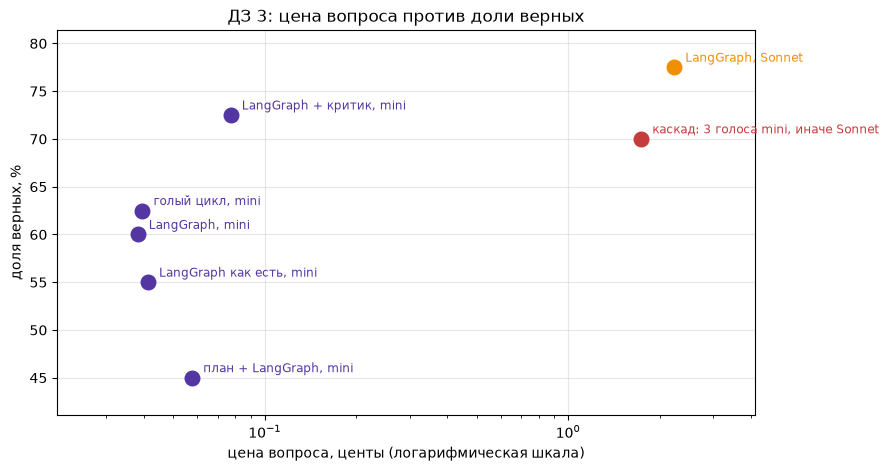

In [32]:
def color_of(tag):
    return COLORS["red"] if "каскад" in tag else COLORS["amber"] if "Sonnet" in tag else COLORS["teal"] if "smolagents" in tag else COLORS["violet"]

def money_chart(tags, path, title):
    table = report(tags)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.set_xscale("log")
    for _, r in table.iterrows():
        ax.scatter(r["центов на вопрос"], r["доля"] * 100, s=110, color=color_of(r["конфигурация"]), zorder=3)
    ax.margins(x=0.15, y=0.12)
    fig.canvas.draw()
    placed = []
    for _, r in table.sort_values("центов на вопрос").iterrows():
        for dx, dy in [(8, 4), (8, -12), (-8, 4), (-8, -12), (8, 16), (8, -24)]:
            label = ax.annotate(r["конфигурация"], (r["центов на вопрос"], r["доля"] * 100), xytext=(dx, dy), textcoords="offset points",
                                fontsize=8.5, ha="left" if dx > 0 else "right", color=color_of(r["конфигурация"]))
            box = label.get_window_extent()
            if not any(box.overlaps(b) for b in placed) or dy == -24:
                break
            label.remove()
        placed.append(box)
    ax.set_xlabel("цена вопроса, центы (логарифмическая шкала)"); ax.set_ylabel("доля верных, %")
    ax.set_title(title); ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return table

TABLE = money_chart(ROWS, "img/money_all.png", "ДЗ 3: цена вопроса против доли верных")
TABLE

In [33]:
from langchain.agents.middleware import ModelCallLimitMiddleware

def capped_agent(limit):
    return create_agent(lc_model(CHEAP), tools=LC_TOOLS, system_prompt=AGENT_SYSTEM,
                        middleware=[ModelCallLimitMiddleware(run_limit=limit, exit_behavior="end")])

TAG["now"] = "потолок"
CAP = None
for t in tasks[:10]:
    before = len(CALLS)
    answer = capped_agent(2).invoke({"messages": [{"role": "user", "content": t["question"]}]})["messages"][-1].content
    if "limit" in str(answer).lower():
        CAP = {"вопрос": t["question"], "ответ LangGraph после обрыва": answer, "вызовов модели": len(CALLS) - before,
               "ответ голого цикла при max_steps=2": bare_agent(t["question"], max_steps=2), "эталон": t["answer"]}
        break
CAP

{'вопрос': 'On what date did Ukraine boycott the closing ceremony of the 2026 Winter Paralympics?',
 'ответ LangGraph после обрыва': 'Model call limits exceeded: run limit (2/2)',
 'вызовов модели': 2,
 'ответ голого цикла при max_steps=2': 'Ukraine boycotted the closing ceremony of the 2026 Winter Paralympics on March 15, 2026.',
 'эталон': '15 March'}

In [34]:
from langchain.agents.middleware import HumanInTheLoopMiddleware, ModelCallLimitMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

@tool
def send_summary(to: str, text: str) -> str:
    """Send a short summary to a colleague by email. Irreversible."""
    return f"sent to {to}: {text}"

TAG["now"] = "человек в контуре"
guarded = create_agent(lc_model(CHEAP), tools=LC_TOOLS + [send_summary], system_prompt=AGENT_SYSTEM.replace(" reply with the short answer only, no explanation", " report what you did"),
                       checkpointer=InMemorySaver(), middleware=[HumanInTheLoopMiddleware(interrupt_on={"send_summary": True})])
thread = {"configurable": {"thread_id": "demo-1"}, "recursion_limit": 14}
out = guarded.invoke({"messages": [{"role": "user", "content": "Find who won the 2026 FIFA World Cup final and email a one-line summary to boss@example.com"}]}, thread)
out["__interrupt__"][0].value["action_requests"]

[{'name': 'send_summary',
  'args': {'to': 'boss@example.com',
   'text': 'Spain won the 2026 FIFA World Cup final against Argentina.'},
  'description': "Tool execution requires approval\n\nTool: send_summary\nArgs: {'to': 'boss@example.com', 'text': 'Spain won the 2026 FIFA World Cup final against Argentina.'}"}]

In [35]:
out = guarded.invoke(Command(resume={"decisions": [{"type": "reject", "message": "Добавь в письмо счёт финала"}]}), thread)
out.get("__interrupt__", [None])[0].value["action_requests"] if out.get("__interrupt__") else out["messages"][-1].content

[{'name': 'send_summary',
  'args': {'to': 'boss@example.com',
   'text': 'Spain won the 2026 FIFA World Cup final against Argentina with a score of 1-0.'},
  'description': "Tool execution requires approval\n\nTool: send_summary\nArgs: {'to': 'boss@example.com', 'text': 'Spain won the 2026 FIFA World Cup final against Argentina with a score of 1-0.'}"}]

In [36]:
out = guarded.invoke(Command(resume={"decisions": [{"type": "approve"}]}), thread)
print(out["messages"][-1].content)
print("сообщений в сохранённом состоянии:", len(guarded.get_state(thread).values["messages"]))

I found that Spain won the 2026 FIFA World Cup final against Argentina with a score of 1-0. I sent a one-line summary to boss@example.com.
сообщений в сохранённом состоянии: 16


In [37]:
by_id = {t["id"]: t for t in tasks}
ANSWERS = pd.DataFrame([{"конфигурация": tag, "id": r["id"], "вопрос": by_id[r["id"]]["question"], "эталон": by_id[r["id"]]["answer"],
                         "ответ": str(r["answer"]).strip(), "верно": r["ok"]} for tag in ROWS for r in RESULTS[tag]])
import gzip
SNAPSHOT.write_bytes(gzip.compress(json.dumps(WIKI_CACHE, ensure_ascii=False).encode("utf-8")))
print("запросов к Википедии без ответа после всех попыток:", len(WIKI_ERRORS))
ANSWERS.to_csv("results/answers.csv", index=False, encoding="utf-8")
pd.DataFrame(CALLS).drop(columns=["messages"], errors="ignore").to_csv("results/calls.csv", index=False, encoding="utf-8")
ANSWERS.pivot(index="id", columns="конфигурация", values="верно").sum().to_frame("верно")

запросов к Википедии без ответа после всех попыток: 0


,верно
конфигурация,
"LangGraph + критик, mini",29
"LangGraph как есть, mini",22
"LangGraph, Sonnet",31
"LangGraph, mini",24
"голый цикл, mini",25
"каскад: 3 голоса mini, иначе Sonnet",28
"план + LangGraph, mini",18


In [38]:
T = report(ROWS).set_index("конфигурация")
ok = lambda tag: T.loc[tag, "верно"]
per_q = lambda tag: T.loc[tag, "центов на вопрос"]
per_ok = lambda tag: T.loc[tag, "центов за верный"]
E = {row["исполнение"]: row for row in EMPTY}
TAX_NOTE = (f"Голый цикл: {E['голый цикл']['токенов в первом вызове']} токенов и {E['голый цикл']['байт в первом запросе']} байт в первом запросе; "
            f"LangGraph после починки: {E['LangGraph']['токенов в первом вызове']} токенов и {E['LangGraph']['байт в первом запросе']} байт. "
            f"Перенос вслепую ({E['LangGraph как есть']['токенов в первом вызове']} токенов) легче, потому что tool(fn) молча выбросил описания "
            f"аргументов, а граф обрывался по recursion_limit вместо ответа: {ok(LG_RAW)} против {ok(LG)} после починки. "
            "Польза фреймворка не в базовом цикле, а в том, что критик графом, лимит вызовов и остановка на подтверждение человеком пишутся в несколько строк.")
# выводы написаны после чтения итоговой таблицы и ответов (results/answers.csv), текст в conclusions.json
while not Path("conclusions.json").exists():
    time.sleep(5)
NOTES = json.loads(Path("conclusions.json").read_text(encoding="utf-8"))
CONCLUSIONS = NOTES["conclusions"]

def md_table(df):
    head = "| " + " | ".join(map(str, df.columns)) + " |\n|" + "---|" * len(df.columns)
    return head + "\n" + "\n".join("| " + " | ".join(str(v).replace("\n", " ").replace("|", "/") for v in row) + " |" for row in df.values)

TABLE = report(ROWS)
spent = sum(c["cost"] for c in CALLS)
cas, strong = TABLE[TABLE["конфигурация"] == CASCADE].iloc[0], TABLE[TABLE["конфигурация"] == STRONG_ROW].iloc[0]
readme = f"""# ДЗ 3. Фреймворк, критик, голосование

Агент из первой домашки на {len(tasks)} вопросах: `fresh-0` … `fresh-{SEMINAR_N - 1}` из стартового набора и все двадцать своих
русских `fresh-{OWN_FROM}` … `fresh-144` (`hw1/data/fresh_2026.jsonl`). Инструменты `web_search` и `page_find` с параметром `lang`:
свои вопросы о событиях русской Википедии. Модели: `{CHEAP}` и `{STRONG}`. Фреймворк: LangGraph.
Запуск: `homework03.ipynb`, ключ `OPENROUTER_API_KEY` в `.env` или в секретах Colab, Run All. Прогон стоил ${spent:.2f}
(все вызовы через один `httpx.Client` со счётчиком `usage.cost`, журнал в `results/calls.csv`).
Ответы каждой конфигурации на каждый вопрос: `results/answers.csv`.

## Итог

{md_table(TABLE)}

![цена вопроса против доли верных](img/money_all.png)

- {CONCLUSIONS[0]}
- {CONCLUSIONS[1]}

## Налог фреймворка на пустом запросе

{md_table(pd.DataFrame(EMPTY))}

Разница в первом вызове: **{TAX:+d} токенов**. {TAX_NOTE}

## Критик и каскад

- Критик: исправил **{FIXED}**, испортил **{BROKEN}**.
- Каскад: наверх ушло **{N_ESCALATED} из {len(tasks)}** ({N_ESCALATED / len(tasks):.0%}); цена верного ответа {cas["центов за верный"]} цента против {strong["центов за верный"]} у сильной модели.

## Проверка проверки

{md_table(pd.DataFrame(CHECK))}

{CHECK_NOTE}

## Потолок на деньги

Лимит в два вызова модели (`ModelCallLimitMiddleware`):

{md_table(pd.DataFrame([CAP]).T.reset_index().set_axis(["", "значение"], axis=1)) if CAP else "на первых десяти вопросах лимит не сработал"}
"""
Path("README.md").write_text(readme, encoding="utf-8")
print(readme)

# ДЗ 3. Фреймворк, критик, голосование

Агент из первой домашки на 40 вопросах: `fresh-0` … `fresh-19` из стартового набора и все двадцать своих
русских `fresh-125` … `fresh-144` (`hw1/data/fresh_2026.jsonl`). Инструменты `web_search` и `page_find` с параметром `lang`:
свои вопросы о событиях русской Википедии. Модели: `openai/gpt-4o-mini` и `anthropic/claude-sonnet-4.6`. Фреймворк: LangGraph.
Запуск: `homework03.ipynb`, ключ `OPENROUTER_API_KEY` в `.env` или в секретах Colab, Run All. Прогон стоил $1.69
(все вызовы через один `httpx.Client` со счётчиком `usage.cost`, журнал в `results/calls.csv`).
Ответы каждой конфигурации на каждый вопрос: `results/answers.csv`.

## Итог

| конфигурация | верно | доля | вызовов на вопрос | токенов на вопрос | центов на вопрос | центов за верный |
|---|---|---|---|---|---|---|
| голый цикл, mini | 25/40 | 0.625 | 3.9 | 2335 | 0.0395 | 0.0633 |
| LangGraph как есть, mini | 22/40 | 0.55 | 4.2 | 2604 | 0.0412 | 0.0749 |
| LangGraph, mini | 24/40 | 0.6 |